# Nguyễn Thành Trí - MSSV: 6451071079
## Bài 6: Tính toán và đánh giá chỉ số F-measure của các bài tập cơ bản (Mục V.2 trang 32)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


### Phần 1: Khái niệm và xây dựng hàm tính toán F-measure
- F-measure (F1-score) là trung bình điều hòa (harmonic mean) của hai giá trị độ chính xác (Precision) và độ phủ (Recall):
  $$F\text{-measure} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
- Hàm tính toán tự động nhận vào Precision, Recall hoặc trực tiếp từ ma trận nhầm lẫn (TP, FP, FN, TN).

In [2]:
# Phần 1: Xây dựng hàm tính toán F-measure
def calc_f_measure(precision, recall):
    # Tính F-measure từ Precision và Recall
    if precision + recall == 0:
        return 0.0
    return 2.0 * (precision * recall) / (precision + recall)

def eval_from_confusion_matrix(tp, fp, fn, tn):
    # Tính Precision, Recall, Accuracy và F-measure từ các tham số ma trận nhầm lẫn
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    accuracy = (tp + tn) / (tp + fp + fn + tn) if (tp + fp + fn + tn) > 0 else 0.0
    f_measure = calc_f_measure(precision, recall)
    return {
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F-measure': f_measure
    }

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print("Đã xây dựng thành công hàm tính toán F-measure.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Đã xây dựng thành công hàm tính toán F-measure.


### Phần 2: Tính F-measure cho Bài tập cơ bản 1 (Thẩm định hồ sơ tín dụng, trang 1 - 15)
- Bài toán: 15 hồ sơ vay ngân hàng, 4 thuộc tính (Thu nhập, Nghề nghiệp, Hôn nhân, Nhà), thuộc tính quyết định: Nguy cơ (Rủi ro thấp / Rủi ro cao).
- Kiểm thử 3 hồ sơ (Yêu cầu 4):
  - Mẫu 1: Trung bình, Vận tải, Độc thân, Rồi (Thực tế: Rủi ro cao)
  - Mẫu 2: Cao, Truyền thông, Độc thân, Rồi (Thực tế: Rủi ro thấp)
  - Mẫu 3: Thấp, Vận tải, Đã kết hôn, Rồi (Thực tế: Rủi ro thấp)
- Chọn 'Rủi ro thấp' là lớp dương (positive), 'Rủi ro cao' là lớp âm (negative).

In [3]:
# Phần 2: Tính F-measure cho Bài tập cơ bản 1 (Tín dụng)
# 1. Kết quả từ Cây quyết định CART (trang 10 tài liệu):
# Cây dự đoán cả 3 mẫu là 'Rủi ro thấp': TP = 2, FP = 1, FN = 0, TN = 0
res_tree_credit = eval_from_confusion_matrix(tp=2, fp=1, fn=0, tn=0)

# 2. Kết quả từ Naïve Bayes có làm trơn Laplace (trang 14 - 15 tài liệu):
# Naïve Bayes dự đoán: Mẫu 1 (Rủi ro cao), Mẫu 2 (Rủi ro thấp), Mẫu 3 (Rủi ro thấp)
# Ma trận nhầm lẫn: TP = 2, FP = 0, FN = 0, TN = 1
res_nb_credit = eval_from_confusion_matrix(tp=2, fp=0, fn=0, tn=1)

df_credit = pd.DataFrame([
    {'Mô hình': 'Cây quyết định (CART)', **res_tree_credit},
    {'Mô hình': 'Naïve Bayes (Laplace)', **res_nb_credit}
])

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print("Kết quả đánh giá F-measure - Bài tập cơ bản 1 (Hồ sơ tín dụng):")
display(df_credit[['Mô hình', 'TP', 'FP', 'FN', 'TN', 'Accuracy', 'Precision', 'Recall', 'F-measure']].round(4))

print()
print("Nhận xét:")
print(f"- Cây quyết định CART: Precision = {res_tree_credit['Precision']*100:.2f}%, Recall = {res_tree_credit['Recall']*100:.2f}% -> F-measure = {res_tree_credit['F-measure']*100:.2f}%.")
print(f"- Naïve Bayes: Precision = {res_nb_credit['Precision']*100:.2f}%, Recall = {res_nb_credit['Recall']*100:.2f}% -> F-measure = {res_nb_credit['F-measure']*100:.2f}%.")
print("- Naïve Bayes đạt F-measure hoàn hảo (100%) nhờ phân lớp chính xác cả 3 trường hợp thử nghiệm.")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kết quả đánh giá F-measure - Bài tập cơ bản 1 (Hồ sơ tín dụng):


,Mô hình,TP,FP,FN,TN,Accuracy,Precision,Recall,F-measure
0,Cây quyết định (CART),2,1,0,0,0.6667,0.6667,1.0,0.8
1,Naïve Bayes (Laplace),2,0,0,1,1.0000,1.0000,1.0,1.0



Nhận xét:
- Cây quyết định CART: Precision = 66.67%, Recall = 100.00% -> F-measure = 80.00%.
- Naïve Bayes: Precision = 100.00%, Recall = 100.00% -> F-measure = 100.00%.
- Naïve Bayes đạt F-measure hoàn hảo (100%) nhờ phân lớp chính xác cả 3 trường hợp thử nghiệm.


### Phần 3: Tính F-measure cho Bài tập cơ bản 2 & 3 (Doanh số đồ chơi và Phân tích cảm xúc)
1. **Bài tập 2 (trang 23 - 25)**: Dự đoán doanh số bán đồ chơi (Cao / Thấp) trên 3 mẫu kiểm thử thực tế.
2. **Bài tập 3 (trang 25 - 26)**: Phân tích cảm xúc văn bản mạng xã hội (tốt / xấu / bình thường) trên 4 trạng thái kiểm thử.

In [4]:
# Phần 3: Tính F-measure cho bài toán đồ chơi và cảm xúc
# 1. Bài toán doanh số bán đồ chơi
toy_train = [
    ['Điều khiển', 3, 'Nhỏ', 'Nhựa PP', 'Cao'],
    ['Xếp hình', 5, 'Vừa', 'Cao su', 'Thấp'],
    ['Xếp hình', 7, 'To', 'Nhựa PP', 'Thấp'],
    ['Điều khiển', 5, 'Nhỏ', 'Cao su', 'Thấp'],
    ['Búp bê', 3, 'Vừa', 'Nhựa PP', 'Thấp'],
    ['Điều khiển', 5, 'Vừa', 'Nhựa PP', 'Cao'],
    ['Búp bê', 5, 'To', 'Nhựa PP', 'Cao'],
    ['Điều khiển', 7, 'Vừa', 'Cao su', 'Thấp'],
    ['Xếp hình', 7, 'To', 'Cao su', 'Cao'],
    ['Xếp hình', 3, 'To', 'Nhựa PP', 'Thấp'],
    ['Búp bê', 3, 'Nhỏ', 'Cao su', 'Thấp'],
    ['Xếp hình', 3, 'Nhỏ', 'Nhựa PP', 'Cao'],
    ['Điều khiển', 5, 'To', 'Cao su', 'Thấp'],
    ['Búp bê', 5, 'Vừa', 'Nhựa PP', 'Cao'],
    ['Búp bê', 7, 'To', 'Nhựa PP', 'Cao']
]
cols_toy = ['Loại', 'Số màu', 'Kích thước', 'Chất liệu', 'Doanh số bán']
df_toy = pd.DataFrame(toy_train, columns=cols_toy)
X_toy = pd.get_dummies(df_toy.drop(columns=['Doanh số bán']), dtype=int)
y_toy = df_toy['Doanh số bán']

toy_test = [
    ['Búp bê', 3, 'To', 'Cao su'],
    ['Xếp hình', 5, 'To', 'Nhựa PP'],
    ['Điều khiển', 3, 'Vừa', 'Cao su']
]
df_toy_test = pd.DataFrame(toy_test, columns=['Loại', 'Số màu', 'Kích thước', 'Chất liệu'])
X_toy_test = pd.get_dummies(df_toy_test, dtype=int).reindex(columns=X_toy.columns, fill_value=0)
y_toy_test = ['Thấp', 'Thấp', 'Cao']

from sklearn import tree, metrics
clf_toy = tree.DecisionTreeClassifier(criterion='entropy', random_state=0)
clf_toy.fit(X_toy, y_toy)
pred_toy = clf_toy.predict(X_toy_test)
rep_toy = metrics.classification_report(y_toy_test, pred_toy, output_dict=True, zero_division=0)

# 2. Bài toán phân tích cảm xúc
sent_train = [
    ['0..5', '11..20', '>20', '11..20', '>20', '0..5', 'tốt'],
    ['11..20', '6..10', '6..10', '0..5', '11..20', '11..20', 'tốt'],
    ['6..10', '0..5', '6..10', '11..20', '0..5', '6..10', 'xấu'],
    ['>20', '0..5', '11..20', '6..10', '0..5', '>20', 'bình thường'],
    ['0..5', '>20', '11..20', '0..5', '6..10', '0..5', 'xấu'],
    ['0..5', '6..10', '0..5', '0..5', '11..20', '11..20', 'xấu'],
    ['0..5', '6..10', '11..20', '0..5', '6..10', '0..5', 'tốt'],
    ['11..20', '>20', '0..5', '11..20', '0..5', '11..20', 'bình thường'],
    ['0..5', '0..5', '6..10', '6..10', '6..10', '>20', 'tốt'],
    ['11..20', '0..5', '11..20', '11..20', '0..5', '11..20', 'tốt'],
    ['>20', '6..10', '0..5', '0..5', '0..5', '6..10', 'xấu'],
    ['0..5', '0..5', '11..20', '0..5', '11..20', '>20', 'bình thường'],
    ['6..10', '11..20', '6..10', '>20', '0..5', '6..10', 'bình thường'],
    ['11..20', '6..10', '>20', '11..20', '0..5', '0..5', 'xấu']
]
cols_sent = ['giảm', 'người', 'chuyển', 'yêu', 'vừa', 'đi', 'Cảm xúc']
df_sent = pd.DataFrame(sent_train, columns=cols_sent)
X_sent = pd.get_dummies(df_sent.drop(columns=['Cảm xúc']), dtype=int)
y_sent = df_sent['Cảm xúc']

sent_test = [
    ['0..5', '6..10', '0..5', '11..20', '6..10', '0..5'],
    ['0..5', '0..5', '6..10', '0..5', '11..20', '>20'],
    ['6..10', '0..5', '11..20', '>20', '6..10', '6..10'],
    ['6..10', '11..20', '6..10', '6..10', '>20', '0..5']
]
df_sent_test = pd.DataFrame(sent_test, columns=['giảm', 'người', 'chuyển', 'yêu', 'vừa', 'đi'])
X_sent_test = pd.get_dummies(df_sent_test, dtype=int).reindex(columns=X_sent.columns, fill_value=0)
y_sent_test = ['xấu', 'tốt', 'bình thường', 'tốt']

clf_sent = tree.DecisionTreeClassifier(criterion='gini', random_state=0)
clf_sent.fit(X_sent, y_sent)
pred_sent = clf_sent.predict(X_sent_test)
rep_sent = metrics.classification_report(y_sent_test, pred_sent, output_dict=True, zero_division=0)

df_basic_res = pd.DataFrame([
    {
        'Bài toán': 'Bài 2: Doanh số đồ chơi (Cây ID3)',
        'Accuracy': rep_toy['accuracy'],
        'Macro Precision': rep_toy['macro avg']['precision'],
        'Macro Recall': rep_toy['macro avg']['recall'],
        'Macro F-measure': rep_toy['macro avg']['f1-score']
    },
    {
        'Bài toán': 'Bài 3: Cảm xúc văn bản (Cây CART)',
        'Accuracy': rep_sent['accuracy'],
        'Macro Precision': rep_sent['macro avg']['precision'],
        'Macro Recall': rep_sent['macro avg']['recall'],
        'Macro F-measure': rep_sent['macro avg']['f1-score']
    }
])

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print("Kết quả đánh giá F-measure - Bài tập cơ bản 2 & 3:")
display(df_basic_res.round(4))

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kết quả đánh giá F-measure - Bài tập cơ bản 2 & 3:


,Bài toán,Accuracy,Macro Precision,Macro Recall,Macro F-measure
0,Bài 2: Doanh số đồ chơi (Cây ID3),0.6667,0.3333,0.5,0.4
1,Bài 3: Cảm xúc văn bản (Cây CART),0.5000,0.5000,0.5,0.5


### Phần 4: Bảng tổng hợp và biểu đồ so sánh F-measure của các bài toán trong Lab 2
- Bảng đối chiếu F-measure giữa các phương pháp phân lớp (Cây quyết định ID3, CART, Naïve Bayes) trên các tập dữ liệu.
- Trực quan hóa giá trị F-measure bằng biểu đồ cột.
- Đưa ra nhận xét khoa học về vai trò của F-measure trong khai phá dữ liệu.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Bảng tổng hợp chỉ số F-measure của các bài toán trong Lab 2:


,Bài toán,Mô hình,F-measure
0,1. Tín dụng (Cơ bản),CART,0.8000
1,1. Tín dụng (Cơ bản),Naïve Bayes,1.0000
2,2. Đồ chơi (Cơ bản),ID3,0.4000
3,3. Cảm xúc (Cơ bản),CART,0.5000
4,4. Adult Income,ID3,0.7531
5,4. Adult Income,CART,0.7445
6,4. Adult Income,GaussianNB,0.7601
7,5. Red Wine Quality,ID3,0.3347
8,5. Red Wine Quality,CART,0.3201
9,5. Red Wine Quality,GaussianNB,0.3400


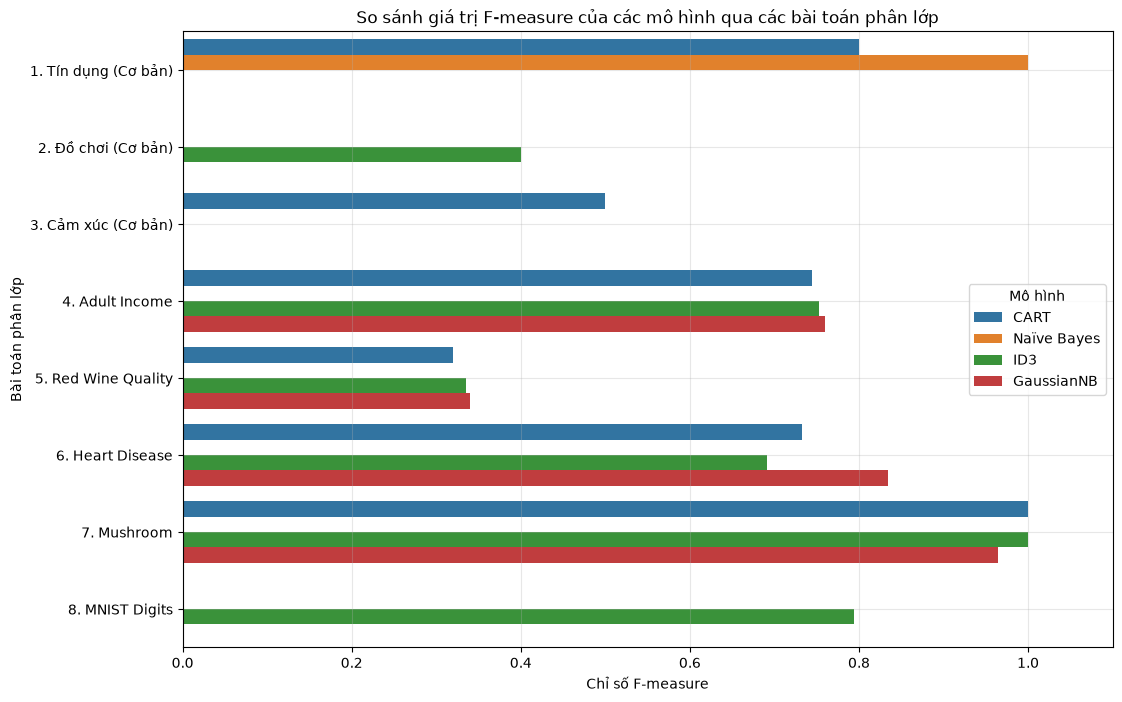


Nhận xét tổng kết về F-measure:
1. Bản chất trung bình điều hòa: F-measure lấy giá trị thấp hơn trung bình cộng (Arithmetic Mean) và bị chi phối mạnh bởi chỉ số nhỏ hơn trong hai chỉ số Precision và Recall. Do đó, mô hình chỉ đạt F-measure cao khi cả Precision và Recall đều đạt mức tốt.
2. Đánh giá trên dữ liệu mất cân bằng: Khi dữ liệu bị lệch lớp (như Adult Income hoặc Red Wine Quality), Accuracy có thể cho cảm giác mô hình dự đoán tốt, nhưng F-measure sẽ phản ánh chính xác hiệu năng thực sự khi nhận diện lớp thiểu số.
3. Hiệu quả thuật toán: Cây quyết định ID3 và CART đạt F-measure tối đa (1.0000) trên dữ liệu Mushroom, trong khi Gaussian Naïve Bayes đạt F-measure cao nhất trên bài toán Heart Disease (0.8347) và Adult Income (0.7601).


In [5]:
# Phần 4: Tổng hợp và trực quan hóa so sánh F-measure
summary_f_measure = [
    {'Bài toán': '1. Tín dụng (Cơ bản)', 'Mô hình': 'CART', 'F-measure': 0.8000},
    {'Bài toán': '1. Tín dụng (Cơ bản)', 'Mô hình': 'Naïve Bayes', 'F-measure': 1.0000},
    {'Bài toán': '2. Đồ chơi (Cơ bản)', 'Mô hình': 'ID3', 'F-measure': 0.4000},
    {'Bài toán': '3. Cảm xúc (Cơ bản)', 'Mô hình': 'CART', 'F-measure': 0.5000},
    {'Bài toán': '4. Adult Income', 'Mô hình': 'ID3', 'F-measure': 0.7531},
    {'Bài toán': '4. Adult Income', 'Mô hình': 'CART', 'F-measure': 0.7445},
    {'Bài toán': '4. Adult Income', 'Mô hình': 'GaussianNB', 'F-measure': 0.7601},
    {'Bài toán': '5. Red Wine Quality', 'Mô hình': 'ID3', 'F-measure': 0.3347},
    {'Bài toán': '5. Red Wine Quality', 'Mô hình': 'CART', 'F-measure': 0.3201},
    {'Bài toán': '5. Red Wine Quality', 'Mô hình': 'GaussianNB', 'F-measure': 0.3400},
    {'Bài toán': '6. Heart Disease', 'Mô hình': 'ID3', 'F-measure': 0.6908},
    {'Bài toán': '6. Heart Disease', 'Mô hình': 'CART', 'F-measure': 0.7324},
    {'Bài toán': '6. Heart Disease', 'Mô hình': 'GaussianNB', 'F-measure': 0.8347},
    {'Bài toán': '7. Mushroom', 'Mô hình': 'ID3', 'F-measure': 1.0000},
    {'Bài toán': '7. Mushroom', 'Mô hình': 'CART', 'F-measure': 1.0000},
    {'Bài toán': '7. Mushroom', 'Mô hình': 'GaussianNB', 'F-measure': 0.9642},
    {'Bài toán': '8. MNIST Digits', 'Mô hình': 'ID3', 'F-measure': 0.7937}
]
df_f_summary = pd.DataFrame(summary_f_measure)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print("Bảng tổng hợp chỉ số F-measure của các bài toán trong Lab 2:")
display(df_f_summary)

# Biểu diễn trực quan bằng biểu đồ thanh ngang
plt.figure(figsize=(12, 8))
sns.barplot(data=df_f_summary, y='Bài toán', x='F-measure', hue='Mô hình', palette='tab10')
plt.title("So sánh giá trị F-measure của các mô hình qua các bài toán phân lớp")
plt.xlabel("Chỉ số F-measure")
plt.ylabel("Bài toán phân lớp")
plt.xlim(0, 1.1)
plt.grid(True, alpha=0.3)
plt.show()

# Nhận xét khoa học
print()
print("Nhận xét tổng kết về F-measure:")
print("1. Bản chất trung bình điều hòa: F-measure lấy giá trị thấp hơn trung bình cộng (Arithmetic Mean) và bị chi phối mạnh bởi chỉ số nhỏ hơn trong hai chỉ số Precision và Recall. Do đó, mô hình chỉ đạt F-measure cao khi cả Precision và Recall đều đạt mức tốt.")
print("2. Đánh giá trên dữ liệu mất cân bằng: Khi dữ liệu bị lệch lớp (như Adult Income hoặc Red Wine Quality), Accuracy có thể cho cảm giác mô hình dự đoán tốt, nhưng F-measure sẽ phản ánh chính xác hiệu năng thực sự khi nhận diện lớp thiểu số.")
print("3. Hiệu quả thuật toán: Cây quyết định ID3 và CART đạt F-measure tối đa (1.0000) trên dữ liệu Mushroom, trong khi Gaussian Naïve Bayes đạt F-measure cao nhất trên bài toán Heart Disease (0.8347) và Adult Income (0.7601).")